In [1]:
import os
import zipfile
import warnings
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_recall_fscore_support
from scipy.signal import medfilt

# Disabilita i warning
warnings.filterwarnings('ignore')

# Configurazione stile grafici (seaborn-v0_8-darkgrid)
try:
    plt.style.use('seaborn-v0_8-darkgrid')
except:
    plt.style.use('ggplot')
sns.set_context("notebook")

# Setup Device con fallback dinamico
if torch.cuda.is_available():
    try:
        # Test moltiplicazione tensori su GPU
        _ = torch.ones(1).cuda() * torch.ones(1).cuda()
        DEVICE = torch.device("cuda")
        print("✅ Device configurato: CUDA (GPU test superato).")
    except Exception as e:
        print(f"⚠️ Errore su CUDA: {e}. Fallback su CPU.")
        DEVICE = torch.device("cpu")
else:
    DEVICE = torch.device("cpu")
    print("ℹ️ CUDA non disponibile. Device configurato: CPU.")

# Path di Kaggle dinamici
BASE_PATH = "/kaggle/input/datasets/christiancorvino/cholec80-mr-sapienza"
if not os.path.exists(BASE_PATH):
    BASE_PATH = "/kaggle/input/cholec80-mr-sapienza"

FEATURES_DIR = "/kaggle/input/cholec80-features/features"
if not os.path.exists(FEATURES_DIR):
    FEATURES_DIR = "/kaggle/input/datasets/christiancorvino/cholec80-features/features"

WORKING_DIR = "/kaggle/working"
RESULTS_DIR = os.path.join(WORKING_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Iperparametri globali
NUM_CLASSES = 7
FEATURE_DIM = 2048 # Dimensione standard ResNet50
D_MODEL = 512
NUM_HEADS = 8
NUM_LAYERS = 4
DROPOUT = 0.5
BATCH_SIZE = 1 # Elaboriamo 1 video intero alla volta
EPOCHS = 30
LEARNING_RATE = 1e-4
WARMUP_EPOCHS = 5
MASKING_PROB = 0.3 # Probabilità oscuramento blocchi

CLASSES = [
    'Preparation', 'CalotTriangleDissection', 'ClippingCutting', 
    'GallbladderDissection', 'GallbladderPackaging', 
    'CleaningCoagulation', 'GallbladderRetraction'
]

✅ Device configurato: CUDA (GPU test superato).


In [2]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        """
        Focal Loss per penalizzare maggiormente gli errori sulle classi difficili.
        """
        super(FocalLoss, self).__init__()
        self.gamma = gamma
        self.reduction = reduction
        self.alpha = alpha

    def forward(self, inputs, targets):
        ce_loss = nn.functional.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss

def sequence_masking(features, mask_prob=0.1, block_size=5):
    """
    Sequence Masking (TimeOut): Azzera casualmente dei blocchi consecutivi 
    nelle features per ridurre l'overfitting.
    features: Tensore di shape [T, Feature_Dim]
    """
    if mask_prob <= 0:
        return features
    
    seq_len = features.size(0)
    # Calcola il numero di blocchi da oscurare
    num_blocks = max(1, int((seq_len * mask_prob) / block_size))
    
    masked_features = features.clone()
    for _ in range(num_blocks):
        # Sceglie un punto di partenza casuale
        start_idx = torch.randint(0, max(1, seq_len - block_size), (1,)).item()
        masked_features[start_idx : start_idx + block_size, :] = 0.0
        
    return masked_features

In [3]:
class Cholec80Dataset(Dataset):
    def __init__(self, feature_dir, annotations_dir, video_ids, is_train=True):
        self.feature_dir = feature_dir
        self.annotations_dir = annotations_dir
        self.video_ids = video_ids
        self.is_train = is_train
        
    def __len__(self):
        return len(self.video_ids)
    
    def __getitem__(self, idx):
        vid_id = self.video_ids[idx]
        
        # Caricamento Features spaziali (.npy) - RISOLTO IL NOME DEL FILE
        feat_path = os.path.join(self.feature_dir, f"video{vid_id:02d}_features.npy")
        if not os.path.exists(feat_path):
            raise FileNotFoundError(f"Feature non trovate nel percorso: {feat_path}")
        
        features = torch.tensor(np.load(feat_path), dtype=torch.float32) # [T, 2048]
        
        # Caricamento Annotazioni Fasi
        ann_path = os.path.join(self.annotations_dir, f"video{vid_id:02d}-phase.txt")
        df = pd.read_csv(ann_path, sep='\t', header=0)
        labels = df.iloc[:, 1].values
        
        label_to_idx = {cls: i for i, cls in enumerate(CLASSES)}
        target = torch.tensor([label_to_idx[l] for l in labels], dtype=torch.long)
        
        # --- FIX: ALLINEAMENTO FRAMERATE ---
        num_features = features.size(0)
        num_labels = target.size(0)
        
        # Se le etichette sono molte di più, troviamo il fattore di scala (es. 25 fps / 1 fps = 25)
        if num_labels > num_features:
            step = num_labels // num_features
            target = target[::step] # Prende un'etichetta ogni 'step' frame
            
        # Per sicurezza pareggiamo le lunghezze finali (se c'è una discrepanza di 1-2 frame)
        min_len = min(features.size(0), target.size(0))
        features = features[:min_len]
        target = target[:min_len]
        
        # Applica augmentation solo in training
        if self.is_train:
            features = sequence_masking(features, mask_prob=MASKING_PROB)
            
        return features, target

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=20000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)
        
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)
        pe[:, 0, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)

    def forward(self, x):
        """ x shape attesa: [T, B, D] """
        x = x + self.pe[:x.size(0)]
        return self.dropout(x)

class TemporalTransformer(nn.Module):
    def __init__(self, input_dim=2048, d_model=512, num_heads=8, num_layers=4, num_classes=7, dropout=0.3):
        super(TemporalTransformer, self).__init__()
        self.d_model = d_model
        
        # Proiezione 2048 -> d_model
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model, dropout)
        
        # Multi-Head Attention Encoder
        encoder_layers = nn.TransformerEncoderLayer(
            d_model=d_model, 
            nhead=num_heads, 
            dim_feedforward=d_model*4, 
            dropout=dropout
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers)
        
        # Output Head
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes)
        )
        
    def forward(self, src):
        # src_shape: [B, T, D]. Transformer si aspetta [T, B, D]
        src = src.transpose(0, 1) 
        
        src = self.input_proj(src) * math.sqrt(self.d_model)
        src = self.pos_encoder(src)
        output = self.transformer_encoder(src)
        
        output = output.transpose(0, 1) # Torna a [B, T, D_model]
        logits = self.classifier(output) # [B, T, NUM_CLASSES]
        return logits

In [5]:
def train_one_epoch(model, dataloader, optimizer, criterion, scheduler, epoch):
    model.train()
    running_loss = 0.0
    all_preds, all_targets = [], []
    
    for features, targets in dataloader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        
        optimizer.zero_grad()
        logits = model(features)
        
        # Appiattimento per calcolo loss: [B*T, C]
        logits = logits.view(-1, NUM_CLASSES)
        targets = targets.view(-1)
        
        loss = criterion(logits, targets)
        loss.backward()
        
        # Gradient clipping: Cruciale nei Transformer
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        running_loss += loss.item()
        
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())
        
    # Lo scheduler in questa implementazione fa lo step ad ogni epoca
    scheduler.step()
    
    acc = accuracy_score(all_targets, all_preds)
    return running_loss / len(dataloader), acc

def validate(model, dataloader, criterion):
    model.eval()
    running_loss = 0.0
    all_preds, all_targets = [], []
    
    with torch.no_grad():
        for features, targets in dataloader:
            features, targets = features.to(DEVICE), targets.to(DEVICE)
            logits = model(features)
            
            logits = logits.view(-1, NUM_CLASSES)
            targets = targets.view(-1)
            
            loss = criterion(logits, targets)
            running_loss += loss.item()
            
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
    acc = accuracy_score(all_targets, all_preds)
    _, _, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro', zero_division=0)
    
    return running_loss / len(dataloader), acc, f1

In [6]:
# Split classico Cholec80: Primi 40 video Train, ultimi 40 Test (usiamo gli ultimi 8 per validazione)
train_videos = list(range(1, 41))
val_videos = list(range(41, 49))

train_dataset = Cholec80Dataset(FEATURES_DIR, os.path.join(BASE_PATH, "phase_annotations"), train_videos, is_train=True)
val_dataset = Cholec80Dataset(FEATURES_DIR, os.path.join(BASE_PATH, "phase_annotations"), val_videos, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model = TemporalTransformer(input_dim=FEATURE_DIM, d_model=D_MODEL, num_heads=NUM_HEADS, 
                            num_layers=NUM_LAYERS, dropout=DROPOUT).to(DEVICE)

# Pesi per focal loss (Assegniamo un peso > 1 alle classi tipicamente minoritarie)
class_weights = torch.tensor([1.0, 1.0, 4.0, 1.0, 4.0, 1.5, 8.0]).to(DEVICE)
criterion = FocalLoss(alpha=class_weights, gamma=2.0)

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-3)

# OneCycleLR gestisce automaticamente il Warmup Lineare e il decadimento Cosine Annealing
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LEARNING_RATE, 
    steps_per_epoch=1, # Dato che facciamo scheduler.step() a fine epoca
    epochs=EPOCHS, 
    pct_start=WARMUP_EPOCHS/EPOCHS 
)

best_f1 = 0.0
model_save_path = os.path.join(RESULTS_DIR, "best_temporal_transformer.pth")

print(f"🚀 Inizio Addestramento sul device: {DEVICE}")
for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, scheduler, epoch)
    val_loss, val_acc, val_f1 = validate(model, val_loader, criterion)
    
    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
          f"Tr Loss: {train_loss:.4f} | Tr Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1 (Macro): {val_f1:.4f}")
    
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), model_save_path)
        print(f" ⭐ Nuovo miglior modello salvato! (F1: {best_f1:.4f})")

🚀 Inizio Addestramento sul device: cuda
Epoch [01/30] | Tr Loss: 2.7750 | Tr Acc: 0.2709 | Val Loss: 2.2115 | Val Acc: 0.3726 | Val F1 (Macro): 0.1472
 ⭐ Nuovo miglior modello salvato! (F1: 0.1472)
Epoch [02/30] | Tr Loss: 2.6883 | Tr Acc: 0.2815 | Val Loss: 2.0518 | Val Acc: 0.4560 | Val F1 (Macro): 0.1600
 ⭐ Nuovo miglior modello salvato! (F1: 0.1600)
Epoch [03/30] | Tr Loss: 2.6311 | Tr Acc: 0.2982 | Val Loss: 1.9733 | Val Acc: 0.3398 | Val F1 (Macro): 0.1412
Epoch [04/30] | Tr Loss: 2.3046 | Tr Acc: 0.3459 | Val Loss: 1.9084 | Val Acc: 0.3489 | Val F1 (Macro): 0.2321
 ⭐ Nuovo miglior modello salvato! (F1: 0.2321)
Epoch [05/30] | Tr Loss: 2.0976 | Tr Acc: 0.3874 | Val Loss: 1.7348 | Val Acc: 0.3503 | Val F1 (Macro): 0.2304
Epoch [06/30] | Tr Loss: 1.8371 | Tr Acc: 0.4326 | Val Loss: 1.3640 | Val Acc: 0.4874 | Val F1 (Macro): 0.3726
 ⭐ Nuovo miglior modello salvato! (F1: 0.3726)
Epoch [07/30] | Tr Loss: 1.7074 | Tr Acc: 0.4445 | Val Loss: 1.3494 | Val Acc: 0.5435 | Val F1 (Macro): 0.

📊 Valutazione Finale (con filtro mediano)...

--- CLASSIFICATION REPORT ---
                         precision    recall  f1-score   support

            Preparation       0.94      0.73      0.82      1305
CalotTriangleDissection       0.93      0.66      0.77      8018
        ClippingCutting       0.26      0.71      0.38      1355
  GallbladderDissection       0.88      0.77      0.82      7838
   GallbladderPackaging       0.29      0.67      0.40       924
    CleaningCoagulation       0.69      0.65      0.67      1744
  GallbladderRetraction       0.09      0.11      0.10       261

               accuracy                           0.70     21445
              macro avg       0.58      0.62      0.57     21445
           weighted avg       0.81      0.70      0.74     21445



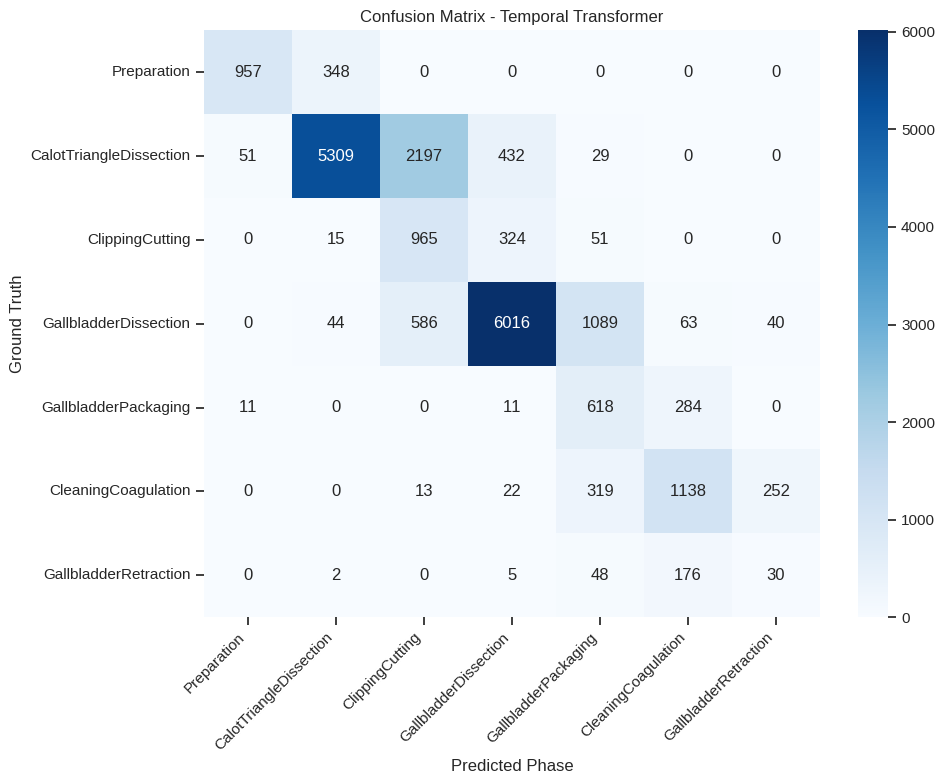

In [7]:
# Carica pesi migliori
model.load_state_dict(torch.load(model_save_path))
model.eval()

all_preds, all_preds_smoothed, all_targets = [], [], []

print("📊 Valutazione Finale (con filtro mediano)...")
with torch.no_grad():
    for features, targets in val_loader:
        features = features.to(DEVICE)
        logits = model(features)
        
        preds = torch.argmax(logits.squeeze(0), dim=1).cpu().numpy()
        targets_np = targets.squeeze(0).cpu().numpy()
        
        # Filtro Mediano per smussare predizioni rumorose
        window_size = 15 # Adatto per sequenze a 25fps
        smoothed_preds = medfilt(preds, window_size)
        
        all_preds.extend(preds)
        all_preds_smoothed.extend(smoothed_preds)
        all_targets.extend(targets_np)

print("\n--- CLASSIFICATION REPORT ---")
# Specifichiamo 'labels' in modo che scikit-learn non vada in errore
# se mancano alcune classi nel validation set.
labels_idx = list(range(NUM_CLASSES))
report = classification_report(
    all_targets, 
    all_preds_smoothed, 
    labels=labels_idx, 
    target_names=CLASSES, 
    zero_division=0
)
print(report)

# Salva report testuale
with open(os.path.join(RESULTS_DIR, "classification_report.txt"), "w") as f:
    f.write(report)

# Matrice di Confusione con Seaborn (aggiunto parametro labels anche qui)
cm = confusion_matrix(all_targets, all_preds_smoothed, labels=labels_idx)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Confusion Matrix - Temporal Transformer")
plt.ylabel('Ground Truth')
plt.xlabel('Predicted Phase')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=300)
plt.show()

In [8]:
# Cella 8: Creazione archivio ZIP finale

import os
import zipfile

def zip_working_dir(source_dir, output_zip):
    print("📦 Compressione dei risultati in corso...")
    # Estraiamo solo il nome del file (es: "output_cholec80.zip")
    output_filename = os.path.basename(output_zip)
    
    with zipfile.ZipFile(output_zip, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for root, dirs, files in os.walk(source_dir):
            for file in files:
                # Escludiamo lo zip stesso confrontando il nome
                if file == output_filename:
                    continue
                file_path = os.path.join(root, file)
                arcname = os.path.relpath(file_path, start=source_dir)
                zipf.write(file_path, arcname)

zip_path = "/kaggle/working/output_cholec80.zip"
zip_working_dir(WORKING_DIR, zip_path)
print(f"✅ Fatto! Tutti i risultati, modelli e log sono zippati in: {zip_path}")

📦 Compressione dei risultati in corso...
✅ Fatto! Tutti i risultati, modelli e log sono zippati in: /kaggle/working/output_cholec80.zip
